In [16]:
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt


#GPU Strategy

In [17]:
gpu_strategy=tf.distribute.MirroredStrategy()
print('No of replicas:',gpu_strategy.num_replicas_in_sync)

No of replicas: 1


#Parameters

In [18]:
AUTOTUNE=tf.data.AUTOTUNE
BATCH_SIZE=32*gpu_strategy.num_replicas_in_sync
IMAGE_SIZE=[180,180]
CLASS_NAMES=['NORMAL','PNEUMONIA']
BUFFER_SIZE=10000

#Load Data

In [19]:
train_images = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/train/images.tfrec"
)
train_paths = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/train/paths.tfrec"
)

ds = tf.data.Dataset.zip((train_images, train_paths))

In [20]:
NORMAL_IMAGES_COUNT = len([f_name for f_name in train_paths if 'NORMAL' in f_name.numpy().decode('utf-8')])
PNEUMONIA_IMAGES_COUNT = len([f_name for f_name in train_paths if 'PNEUMONIA' in f_name.numpy().decode('utf-8')])

print('Normal Images: ', NORMAL_IMAGES_COUNT)
print('Pneumonia Images: ', PNEUMONIA_IMAGES_COUNT)

Normal Images:  1349
Pneumonia Images:  3883


In [21]:
TRAIN_IMAGE_COUNT=NORMAL_IMAGES_COUNT+PNEUMONIA_IMAGES_COUNT
print('Train Image Count: ',TRAIN_IMAGE_COUNT)

Train Image Count:  5232


#Class Weight

In [22]:
weight_for_0 = (1 / NORMAL_IMAGES_COUNT) * (TRAIN_IMAGE_COUNT / 2.0)
weight_for_1 = (1 / PNEUMONIA_IMAGES_COUNT) * (TRAIN_IMAGE_COUNT / 2.0)
class_weight = {0: weight_for_0, 1: weight_for_1}

print('Weight for class 0: {:.2f}'.format(weight_for_0))
print('Weight for class 1: {:.2f}'.format(weight_for_1))

Weight for class 0: 1.94
Weight for class 1: 0.67


#Preprocessing

In [23]:
def preprocessor(image,path):
    images=tf.image.decode_jpeg(image,channels=3)
    images=tf.image.resize(images,IMAGE_SIZE)

    parts=tf.strings.split(path,sep='/')
    if parts[-2]=='PNEUMONIA':
        labels=1
    else:
       labels=0
    return image,labels
ds=ds.map(preprocessor,num_parallel_calls=AUTOTUNE)


#Data spliting

In [24]:
ds=ds.shuffle(BUFFER_SIZE)

TRAIN_SIZE=4200
train_ds=ds.take(TRAIN_SIZE)
val_ds=ds.skip(TRAIN_SIZE)

In [25]:
for image_bytes, label in train_ds.take(1):
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    print("Image shape: ", image.shape)
    print("Label: ", label.numpy())

Image shape:  (920, 1280, 3)
Label:  1


#Cache and Prefetch Data

In [26]:
train_ds=train_ds.cache().batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds=val_ds.cache().batch(BATCH_SIZE).prefetch(AUTOTUNE)

#Data Visualization

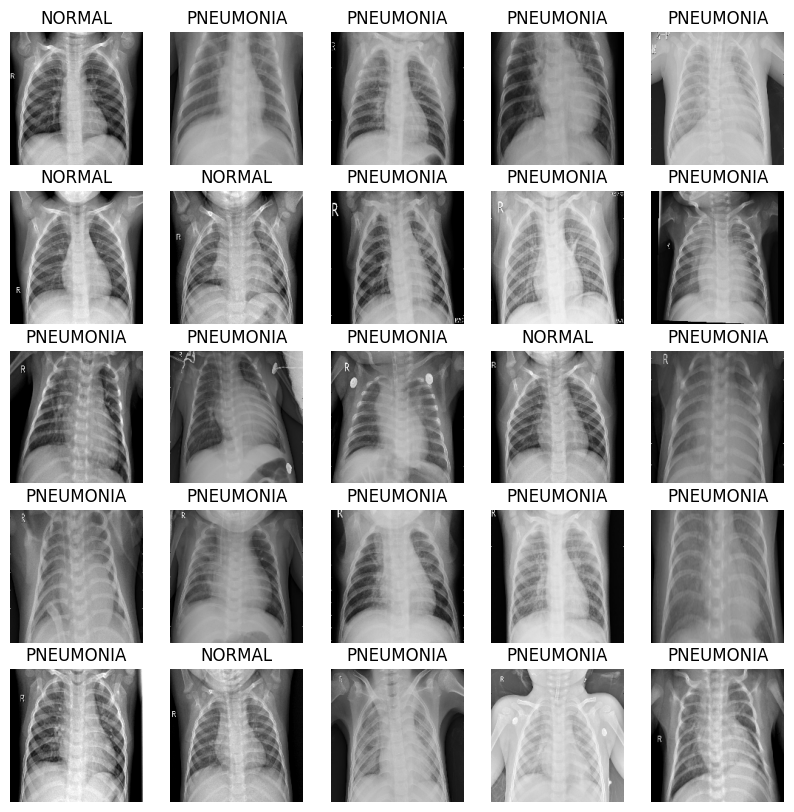

In [27]:
plt.figure(figsize=(10,10))
for image_batch, label_batch in train_ds.take(1):
    for i in range(25):  # Fit the 5x5 grid
        plt.subplot(5,5,i+1)
        # Decode and resize the raw image string locally
        decoded_img = tf.image.decode_jpeg(image_batch[i], channels=3)
        resized_img = tf.image.resize(decoded_img, IMAGE_SIZE)

        plt.imshow(tf.cast(resized_img, tf.float32) / 255.0)
        if label_batch[i]:
            plt.title('PNEUMONIA')
        else:
            plt.title('NORMAL')
        plt.axis('off')

plt.show()

#CNN

In [28]:
def conv_block(filters,inputs):
    x=layers.SeparableConv2D(filters,3,activation='relu',padding='same')(inputs)
    x=layers.SeparableConv2D(filters,3,activation='relu',padding='same')(x)
    x=layers.BatchNormalization()(x)
    x=layers.MaxPool2D(3,strides=2,padding='same')(x)
    return x
def dense_block(units,dropout_rate,inputs):
    x=layers.Dense(units,activation='relu')(inputs)
    x=layers.BatchNormalization()(x)
    x=layers.Dropout(dropout_rate)(x)
    return x


In [29]:
def build_model(inputs):
    inputs=keras.Input(shape=(IMAGE_SIZE[0],IMAGE_SIZE[1],3))
    x=layers.Rescaling(1./255)(inputs)
    x=layers.Conv2D(16,3,activation='relu',padding='same')(x)
    x=layers.Conv2D(16,3,activation='relu',padding='same')(x)
    x=layers.MaxPool2D()(x)


    x=conv_block(32,x)
    x=conv_block(64,x)
    x=conv_block(28,x)
    x=layers.Dropout(0.2)(x)
    x=conv_block(256,x)
    x=layers.Dropout(0.2)(x)

    x=layers.Flatten()(x)
    x=dense_block(512,0.7,x)
    x=dense_block(128,0.5,x)
    x=layers.Dropout(64,0.3,x)(x)

    outputs=layers.Dense(1,activation='sigmoid')(x)
    return keras.Model(inputs=inputs,outputs=outputs)



In [30]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Ensure IMAGE_SIZE and other parameters exist
try:
    IMAGE_SIZE
except NameError:
    IMAGE_SIZE = [180, 180]

# Ensure gpu_strategy exists
try:
    gpu_strategy
except NameError:
    gpu_strategy = tf.distribute.get_strategy() # Fallback to default CPU/GPU single-device strategy

def build_model_fixed():
    inputs = keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
    x = layers.Rescaling(1./255)(inputs)
    x = layers.Conv2D(16, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(16, 3, activation='relu', padding='same')(x)
    x = layers.MaxPool2D()(x)

    x = conv_block(32, x)
    x = conv_block(64, x)
    x = conv_block(28, x)
    x = layers.Dropout(0.2)(x)
    x = conv_block(256, x)
    x = layers.Dropout(0.2)(x)

    x = layers.Flatten()(x)
    x = dense_block(512, 0.7, x)
    x = dense_block(128, 0.5, x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs=inputs, outputs=outputs)

with gpu_strategy.scope():
    model = build_model_fixed()

    metrics = [
        keras.metrics.BinaryAccuracy(),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall')
    ]

    lr_scheduler = keras.optimizers.schedules.ExponentialDecay(
        0.015, decay_steps=10000, decay_rate=0.9, staircase=True
    )
    model.compile(
        optimizer=keras.optimizers.RMSprop(learning_rate=lr_scheduler),
        loss='binary_crossentropy',
        metrics=metrics
    )

In [33]:
import tensorflow as tf

# Helper function to fix the raw image bytes in the dataset pipelines
def parse_and_resize(raw_image_bytes, label):
    # Decode the raw jpeg string bytes
    img = tf.io.decode_jpeg(raw_image_bytes, channels=3)
    # Resize to the model's target input size
    img = tf.image.resize(img, IMAGE_SIZE)
    return img, label

# Unbatch, map the fix, and re-batch the datasets
train_ds_fixed = train_ds.unbatch().map(parse_and_resize, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds_fixed = val_ds.unbatch().map(parse_and_resize, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

checkpoints = keras.callbacks.ModelCheckpoint(
    'model_checkpoints.keras',
    monitor='val_binary_accuracy',
    mode='max',
    save_best_only=True,
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_binary_accuracy',
    mode='max',
    patience=10,
    restore_best_weights=True,
)

# Fit using the fixed pipeline
history = model.fit(
    train_ds_fixed,
    epochs=30,
    validation_data=val_ds_fixed,
    class_weight=class_weight,
    callbacks=[checkpoints, early_stopping]
)

Epoch 1/30
    132/Unknown 205s 191ms/step - binary_accuracy: 0.6885 - loss: 0.7145 - precision: 0.8758 - recall: 0.6833

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


132/132 ━━━━━━━━━━━━━━━━━━━━ 563s 3s/step - binary_accuracy: 0.7552 - loss: 0.5563 - precision: 0.9068 - recall: 0.7486 - val_binary_accuracy: 0.2490 - val_loss: 60.6271 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 33s 245ms/step - binary_accuracy: 0.8998 - loss: 0.2650 - precision: 0.9663 - recall: 0.8968 - val_binary_accuracy: 0.2510 - val_loss: 25.9403 - val_precision: 1.0000 - val_recall: 0.0026
Epoch 3/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 33s 246ms/step - binary_accuracy: 0.9231 - loss: 0.2106 - precision: 0.9689 - recall: 0.9265 - val_binary_accuracy: 0.7335 - val_loss: 1.5339 - val_precision: 1.0000 - val_recall: 0.6452
Epoch 4/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 34s 253ms/step - binary_accuracy: 0.9383 - loss: 0.1774 - precision: 0.9764 - recall: 0.9400 - val_binary_accuracy: 0.8886 - val_loss: 0.4398 - val_precision: 0.9985 - val_recall: 0.8529
Epoch 5/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 32s 238ms/step - binary_accuracy: 0.9405 - loss: 0.1696

In [36]:
# Evaluate using the fixed validation dataset containing decoded and resized images
model.evaluate(val_ds_fixed, return_dict=True)

33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 178ms/step - binary_accuracy: 0.9845 - loss: 0.0479 - precision: 0.9922 - recall: 0.9871


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


{'binary_accuracy': 0.9844961166381836,
 'loss': 0.04794983193278313,
 'precision': 0.9922178983688354,
 'recall': 0.9870967864990234}

In [38]:
test_images = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/test/images.tfrec"
)
test_paths = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/test/paths.tfrec"
)
test_ds = tf.data.Dataset.zip((test_images, test_paths))

# Map with the preprocessor to extract the label, then parse/decode raw bytes correctly
test_ds = test_ds.map(preprocessor, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(parse_and_resize, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

model.evaluate(test_ds, return_dict=True)

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 660ms/step - binary_accuracy: 0.8029 - loss: 1.1301 - precision: 0.7623 - recall: 0.9949


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


{'binary_accuracy': 0.8028846383094788,
 'loss': 1.1300503015518188,
 'precision': 0.7622789740562439,
 'recall': 0.9948717951774597}

In [39]:
model.save('model.keras')